# Euler System of Gas Dynamics

In [1]:
import math, numpy
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
from matplotlib import pyplot
from ufl import *
from dune.grid import structuredGrid, reader
from dune.fem.space import dgonb, finiteVolume
from dune.fem.function import gridFunction
from dune.femdg import femDGOperator
from dune.femdg.rk import femdgStepper
from dune.fem.utility import lineSample

The dune-fem-dg module can either used stabilizer DG methods to solve
this type of problem or higher order FV methods based on linear
reconstruction. The following function uses a finite-volume space when
order=0 and a dg space with orthonormal polynomials otherwise.
Note that when a limiter is then used in the scheme, the finite-volume
scheme will use linear reconstruction:

In [2]:
def getSpace( gv, order ):
    return finiteVolume( gridView, dimRange=4 ) if order==0 else\
           dgonb( gridView, dimRange=4, order=order )

Basic model for hyperbolic conservation law

In [3]:
class Model:
    gamma = 1.4
    # helper function
    def toPrim(U):
        v = as_vector( [U[i]/U[0] for i in range(1,3)] )
        kin = dot(v,v) * U[0] / 2
        pressure = (Model.gamma-1)*(U[3]-kin)
        return U[0], v, pressure

    # interface methods for model
    def F_c(t,x,U):
        rho, v, p = Model.toPrim(U)
        return as_matrix( [
                  [rho*v[0], rho*v[1]],
                  [rho*v[0]*v[0] + p, rho*v[0]*v[1]],
                  [rho*v[0]*v[1], rho*v[1]*v[1] + p],
                  [(U[3]+p)*v[0], (U[3]+p)*v[1]] ] )

    # simple 'outflow' boundary conditions on all boundaries
    boundary = {range(1,5): lambda t,x,U: U}

    # interface method needed for LLF and time step control
    def maxWaveSpeed(t,x,U,n):
        rho, v, p = Model.toPrim(U)
        return abs(dot(v,n)) + sqrt(Model.gamma*p/rho)

Add methods for limiting

In [4]:
def velocity(t,x,U):
    _, v ,_ = Model.toPrim(U)
    return v
def physical(t,x,U):
    rho, _, p = Model.toPrim(U)
    return conditional( rho>1e-8, conditional( p>1e-8 , 1, 0 ), 0 )
def jump(t,x,U,V):
    _,_, pL = Model.toPrim(U)
    _,_, pR = Model.toPrim(V)
    return (pL - pR)/(0.5*(pL + pR))
Model.velocity = velocity
Model.physical = physical
Model.jump     = jump

Method to evolve the solution in time

In [5]:
def evolve(space, u_h, limiter="MinMod"):
    lu_h = u_h.localFunction()
    @gridFunction(space.grid,name="rho",order=space.order)
    def rho(e,x):
        lu_h.bind(e)
        return lu_h(x)[0]
    operator = femDGOperator(Model, space, limiter=limiter) # note: that u_h.space fails since not ufl_space
    stepper  = femdgStepper(order=space.order+1 if space.order>0 else 2, operator=operator)
    operator.applyLimiter(u_h)

    t = 0
    saveStep = 0.1
    fig = pyplot.figure(figsize=(30,10))
    rho.plot(gridLines="white", figure=(fig, 131), colorbar=False, clim=[0.125,1])
    c = 1
    while t <= 0.3:
        operator.setTime(t)
        t += stepper(u_h)
        if t > saveStep:
            print(t)
            saveStep += 0.1
            rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
            c += 1

    res = numpy.zeros((2,space.grid.size(0)))
    for i,e in enumerate(space.grid.elements):
        x = e.geometry.center
        res[0][i] = x.two_norm
        res[1][i] = rho(e,e.geometry.toLocal(x))
    return res

A radial Rieman problem

In [6]:
x = SpatialCoordinate(triangle)
initial = conditional(dot(x,x)<0.1,as_vector([1,0,0,2.5]),
                                   as_vector([0.125,0,0,0.25]))

domain = (reader.dgf, "triangle.dgf")

We start with a triangular grid

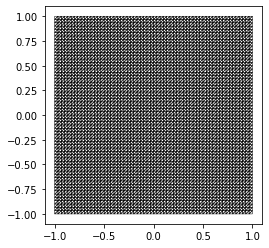

In [7]:
try:
    from dune.polygongrid import polygonGrid
    gridView = polygonGrid( domain, dualGrid=False )
except ImportError:
    print("dune.polygongrid module not found using a simplex grid instead - ignored")
    from dune.alugrid import aluSimplexGrid as simplexGrid
    gridView = simplexGrid( domain, dimgrid=2 )
gridView.plot()

# fix the order to use and storage structure for results
res = {}
order = 1
space = getSpace( gridView, order )

Initial conditions for a radial Rieman problem

First solved on a triangle grid and minmod limiter

femDGOperator: Limiter = MinMod


0.10060404087410266


0.20071331444960347


0.300414234633481


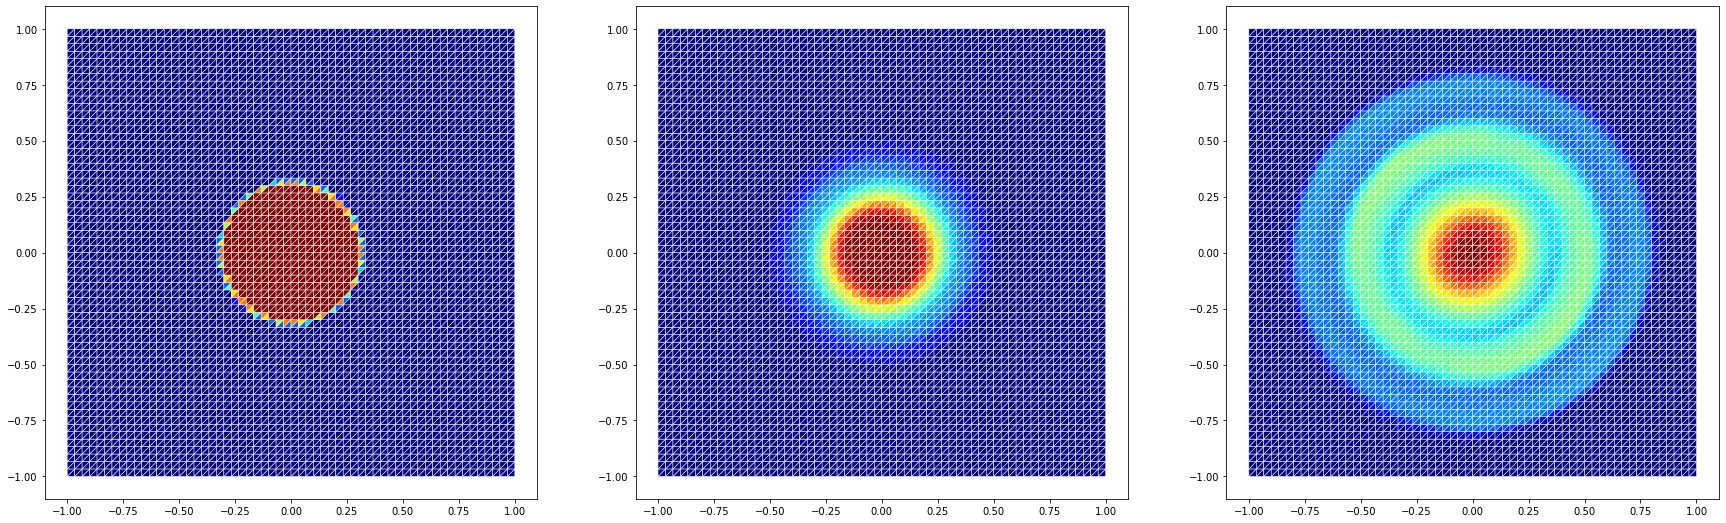

In [8]:
u_h   = space.interpolate( initial, name="solution")
res["simplex (minmod)"] = evolve(space,u_h)

Now a triangle grid without limiter (which of course fails)

femDGOperator: Limiter = unlimited


8.089619106880421e+307


array([[1.39066553, 1.39066553, 1.36743429, ..., 1.36743429, 1.39066553,
        1.39066553],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]])

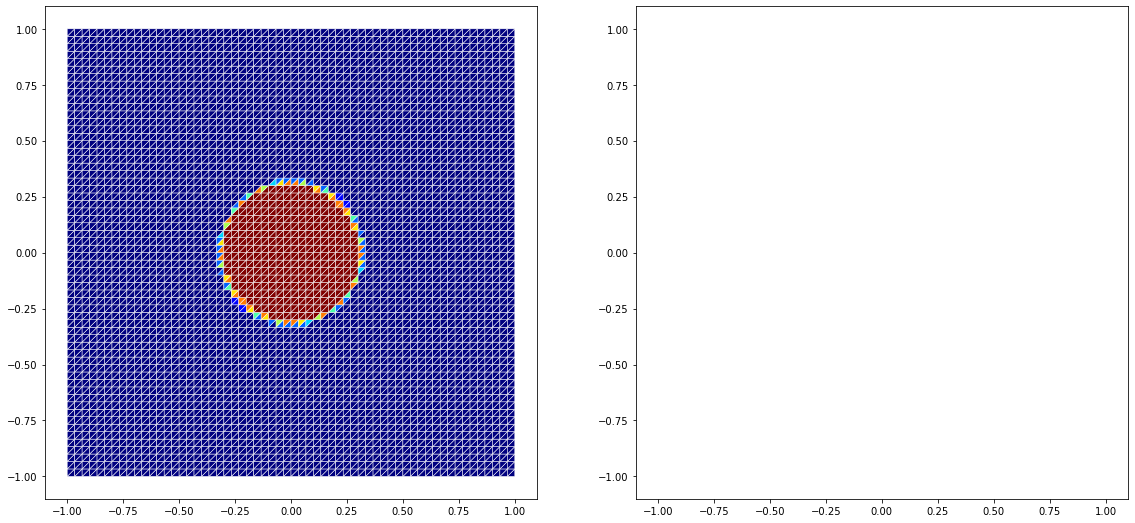

In [9]:
u_h   = space.interpolate( initial, name="solution")
evolve(space,u_h,limiter=None)

Now a finite volume method first without reconstruction on the triangle grid

femDGOperator: Limiter = minmod


0.10189607433521328


0.20197721003711827


0.30031868034558606


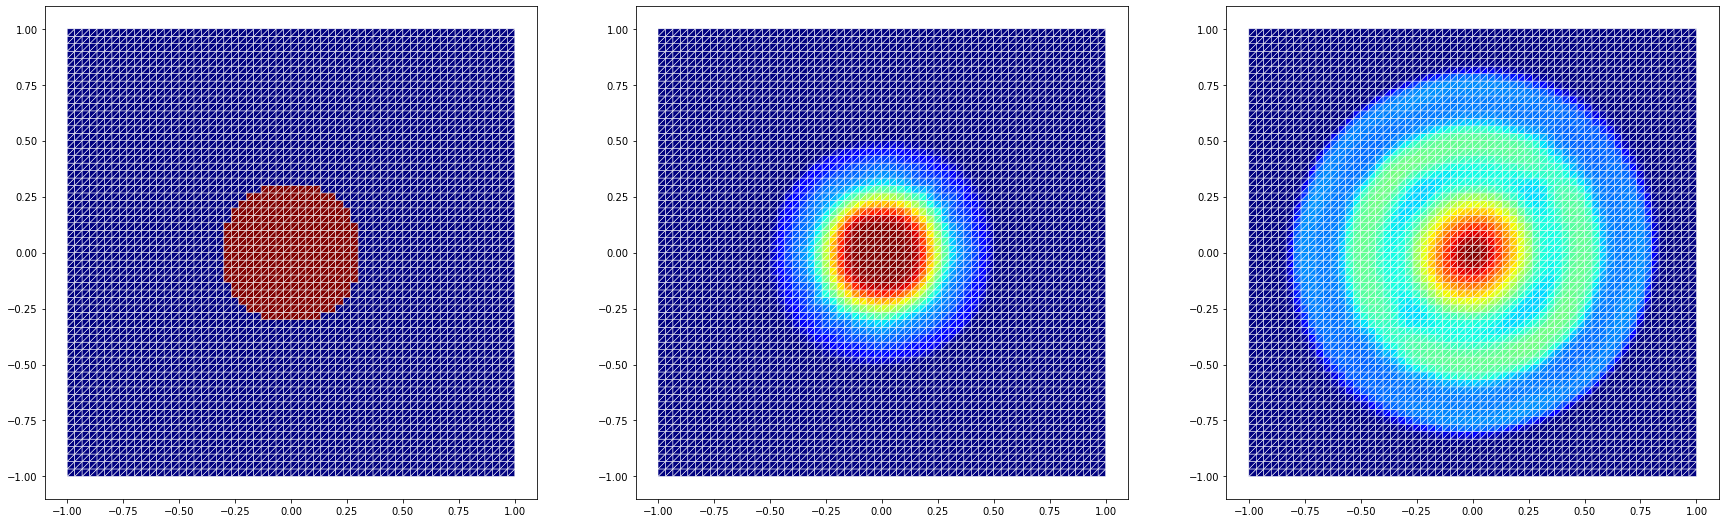

In [10]:
fvspace = getSpace( gridView, 0 )
u_h   = fvspace.interpolate( initial, name="solution")
res["simplex (fv)"] = evolve(fvspace,u_h,limiter="minmod")

and a finite volume method with reconstruction

femDGOperator: Limiter = unlimited


0.10042117076109101


0.20058412951349774


0.30083850698831255


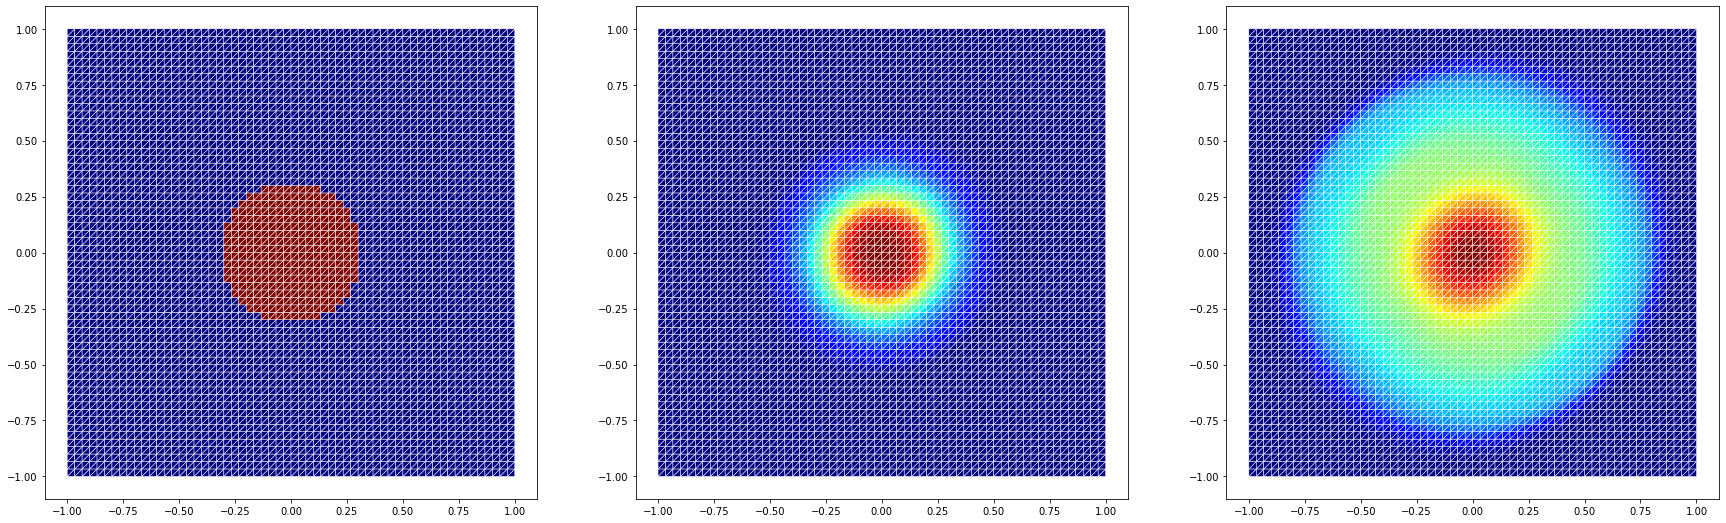

In [11]:
fvspace = getSpace( gridView, 0 )
u_h   = fvspace.interpolate( initial, name="solution")
res["simplex (higher order fv)"] = evolve(fvspace,u_h,limiter=None)

Using a polygonal grid (dual grid of previous grid)

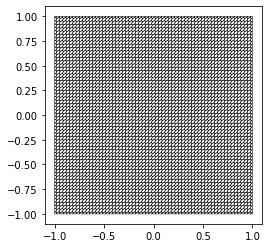

In [12]:
try:
    from dune.polygongrid import polygonGrid
    gridView = polygonGrid( domain, dualGrid=True )
except ImportError:
    print("dune.polygongrid module not found using a simplex grid instead - ignored")
    gridView = simplexGrid( domain, dimgrid=2 )
gridView.plot()
space = getSpace( gridView, order )

Solution with limiter - fails as above without

femDGOperator: Limiter = MinMod


0.10079052613578983


0.20000620030070723


0.30079672643649485


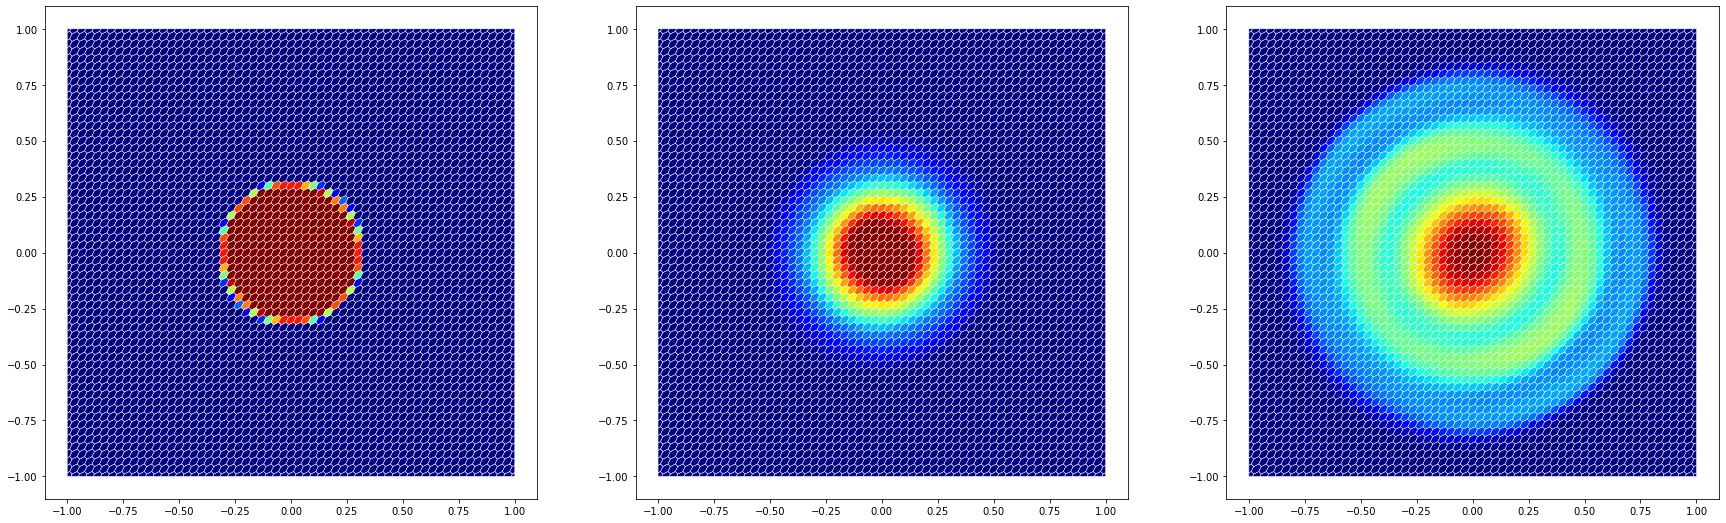

In [13]:
u_h   = space.interpolate( initial, name="solution")
res["polygons (minmod)"] = evolve(space,u_h)

Solutions along the diagonal

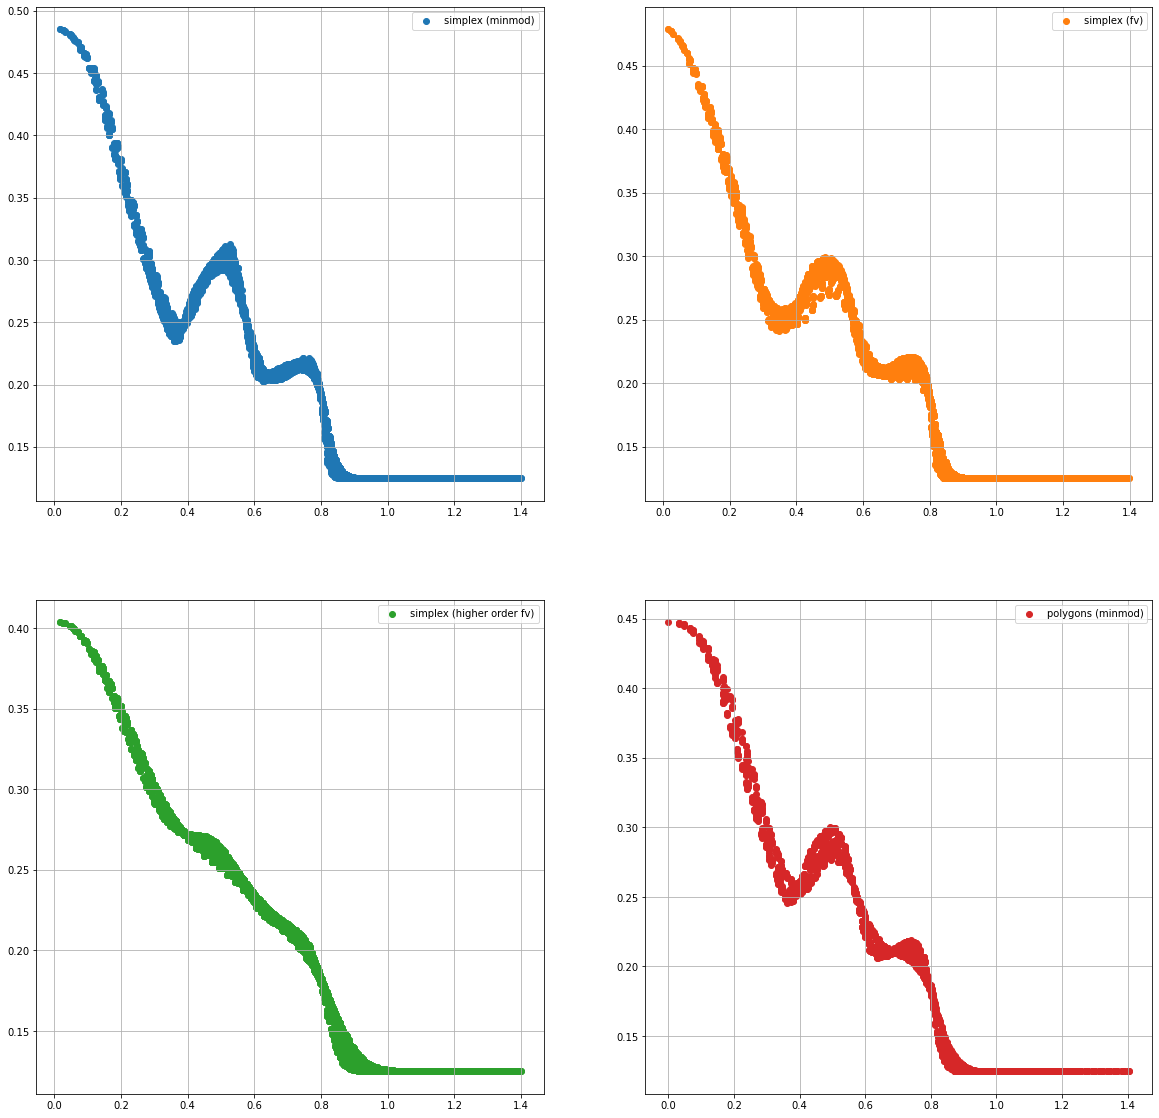

In [14]:
color = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
figure = pyplot.figure(figsize=(20,20))
for i,(k,x) in enumerate(res.items()):
    ax = pyplot.subplot(221+i)
    ax.scatter(x[0],x[1], color=color[i], label=k)
    ax.legend()
    ax.grid(True)
pyplot.show()